# Application 2A — a service with regime changes

**Question:** When does a tree describe latency better than an additive linear model?

For 1,200 independent requests, draw $s\sim U(0,10)$ MB, $q\sim\operatorname{Poisson}(3)$,
and independent $\epsilon\sim N(0,8^2)$ ms, then set
$$y=40+20\cdot\mathbf{1}\{q>3\}+30\cdot\mathbf{1}\{q>3\text{ and }s>5\}+\epsilon.$$
Here $\mathbf{1}\{\text{condition}\}$ is the **indicator function** (also called the
characteristic function of the indicated set): it is 1 when the condition holds and 0 otherwise.
The dot $\cdot$ denotes multiplication. Thus a queue length $q>3$ adds 20 ms;
if the payload also satisfies $s>5$ MB, another 30 ms is added.
Before noise, latency is therefore 40 ms when $q\le3$, 60 ms when $q>3$ and $s\le5$,
and 90 ms when $q>3$ and $s>5$.
The conditional mean is piecewise constant. Gaussian noise is a teaching approximation.

Here $s$ is payload size, $q$ is queue length, and $y$ is the observed latency.
$U(0,10)$ means a uniform distribution; the Poisson queue length has mean 3.
The independent noise $\epsilon$ has mean zero and standard deviation 8 ms.
The **conditional mean** is the average latency for fixed payload and queue values,
before the random noise is added.

We first check how a tree chooses one split, then compare models, select pruning,
inspect stability, and evaluate predictions on held-out requests.
**Cross-validation (CV)** repeatedly fits on part of the training data and scores on
another part. A **fold** is one such group of rows. **Root mean squared error (RMSE)**
is the square root of the average squared prediction error, measured here in milliseconds.
**Standard deviation (SD)** measures variability.

In the code, `X` contains input features and `y` contains target latencies.
A model's `.fit(X, y)` learns from data; `.predict(X_new)` uses the fitted model to
predict new rows without learning again. The main classes and functions are introduced
below, before the cells that first use them.

**Protocol:** seed 17 for simulation, seed 23 for the 60/20/20 split; five-fold training CV selects
pruning. Validation audits frozen choices. No model changes follow the test results.
Run all cells in order with the course `requirements.txt`. See
[the focused guide](02_decision_trees_and_random_forests.pdf). No data download is needed.

## 1. Verify a regression stump using sorted values and prefix sums

**Purpose:** Understand the basic operation inside a regression tree before calling the
library implementation. A **stump** is a tree with one split and two leaves. It asks one
question, such as “is queue length at most 3.5?”, and predicts a constant in each leaf.

For a group of rows $A$, the best constant under squared error is its target mean
$\bar y_A$. The **residual sum of squares (RSS)** is

$$\operatorname{RSS}(A)=\sum_{i\in A}(y_i-\bar y_A)^2.$$

A candidate threshold $t$ for feature $j$ places rows with $x_{ij}\le t$ on the left
and the others on the right. We choose the split minimizing
$\operatorname{RSS}(A_L)+\operatorname{RSS}(A_R)$. RSS has units of squared milliseconds;
it is a total, not an average. `min_leaf` is the minimum number of rows allowed in either leaf.

### How the search works

Sort the rows by one feature and test midpoints between distinct neighboring values.
Thresholds between equal values cannot separate those rows, so they are skipped.
For the first $k$ sorted responses, let $S_k$ be their sum and $Q_k$ their sum of squares.
Then

$$\operatorname{RSS}(A_L)=Q_k-\frac{S_k^2}{k}.$$

Cumulative sums make it possible to evaluate successive splits without repeatedly summing
all rows. The right-child formula uses total sums minus the left sums. The code first
subtracts the overall response mean for better numerical stability; translating all responses
by the same constant does not change RSS or the best split.

### Main functions in the next cell

| Function or operation | Role here |
| --- | --- |
| `stump_candidates(X, y, min_leaf=1)` | Our own function, defined below: returns a table of feature indices, thresholds, and total child RSS. It does not construct a fitted tree. |
| `np.argsort(...)` | Returns row positions that put a feature in increasing order. |
| `np.cumsum(...)` | Computes all cumulative sums used in $S_k$ and $Q_k$. |
| `.reshape(-1, 1)` | Makes a one-feature array into a two-dimensional input table: one row per observation, one column. |
| `pd.DataFrame(...)` / `display(...)` | Organizes candidate results into a table and displays it. |
| `.idxmin()` | Returns the index of the first smallest score; this determines the winner. |
| `np.testing.assert_allclose(...)` | Checks that two numerical calculations agree within tolerance, raising an error if they do not. |

We check **every candidate** on the tiny example $x=(1,2,3,4,5,6)$,
$y=(2,3,2,8,9,10)$ against direct residual sums. The best threshold is 3.5,
with leaf means $7/3$ and 9. A second check ensures repeated feature values are handled correctly.
Candidates are generated in feature order and then threshold order, so exact ties use that order.
The library imports at the top also prepare the later sections.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from time import perf_counter
from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

def stump_candidates(X, y, min_leaf=1):
    rows = []
    centered_y = y - y.mean()
    for feature in range(X.shape[1]):
        order = np.argsort(X[:, feature], kind="stable")
        values = X[order, feature]
        responses = centered_y[order]
        sums = np.cumsum(responses)
        squares = np.cumsum(responses ** 2)
        for k in range(min_leaf, len(y) - min_leaf + 1):
            if values[k - 1] == values[k]:
                continue
            threshold = (values[k - 1] + values[k]) / 2
            left_rss = squares[k - 1] - sums[k - 1] ** 2 / k
            right_sum = sums[-1] - sums[k - 1]
            right_square = squares[-1] - squares[k - 1]
            right_rss = right_square - right_sum ** 2 / (len(y) - k)
            rows.append({"feature": feature, "threshold": threshold,
                         "child RSS": max(0.0, left_rss) + max(0.0, right_rss)})
    return pd.DataFrame(rows)

x_small = np.arange(1, 7, dtype=float).reshape(-1, 1)
y_small = np.array([2, 3, 2, 8, 9, 10], dtype=float)
audit = stump_candidates(x_small, y_small)
direct_rss = []
for threshold in audit["threshold"]:
    left = y_small[x_small[:, 0] <= threshold]
    right = y_small[x_small[:, 0] > threshold]
    direct_rss.append(np.sum((left - left.mean()) ** 2) + np.sum((right - right.mean()) ** 2))
audit["direct RSS"] = direct_rss
np.testing.assert_allclose(audit["child RSS"], direct_rss, atol=1e-10)
np.testing.assert_allclose(audit["child RSS"], [53.2, 39.25, 8/3, 25.25, 46.8])
assert audit.loc[audit["child RSS"].idxmin(), "threshold"] == 3.5
repeated = stump_candidates(np.array([[0.], [0.], [1.], [1.]]), np.array([0., 1., 3., 4.]))
assert repeated["threshold"].tolist() == [0.5]
display(audit)
print("All stump checks passed.")

,feature,threshold,child RSS,direct RSS
0,0,1.5,53.200000,53.200000
1,0,2.5,39.250000,39.250000
2,0,3.5,2.666667,2.666667
3,0,4.5,25.250000,25.250000
4,0,5.5,46.800000,46.800000


All stump checks passed.


## 2. Generate requests and reserve the splits

**Purpose:** Create the data described at the start and separate the rows used to learn
from those used to evaluate predictions.

The Boolean expression `queue > 3` is the indicator in the formula: multiplication treats
`True` as 1 and `False` as 0. The operator `&` means that **both** conditions hold, so
`(queue > 3) & (payload > 5)` activates the additional 30 ms term only in the high regime.
`mean_latency` is the known simulation mean, while `latency` includes random noise.

### Main functions in the next cell

| Function or operation | Role here |
| --- | --- |
| `np.random.default_rng(17)` | Creates a reproducible random-number generator. |
| `rng.uniform`, `rng.poisson`, `rng.normal` | Generate payload sizes, integer queue lengths, and independent Gaussian noise. |
| `train_test_split(...)` | Randomly divides rows into separate partitions. `random_state=23` makes the split reproducible. |
| `train[features].to_numpy()` | Selects the two input columns and converts them to a NumPy array. |
| `plt.subplots(...)` / `ax.scatter(...)` | Creates side-by-side plots of training latency against each feature. |

The first split reserves 20% of the data for testing. The second reserves 25% of the
remaining 80%, giving another 20% of the original data for validation. This yields
**720 training**, **240 validation**, and **240 test** rows. The assertions check that
no row belongs to more than one partition.

Training data fit the models and select pruning. Validation gives an additional check
without changing the selected settings. Test data are reserved until the final evaluation.
Only `payload` and `queue` become inputs; neither the observed target nor the simulator's
known mean is an input feature.

The scatterplots show only training rows. A plot against payload alone mixes different
queue lengths, so several latency levels can occur at the same payload. This is why
looking at both features together will matter.

Rows: {'training': 720, 'validation': 240, 'test': 240}


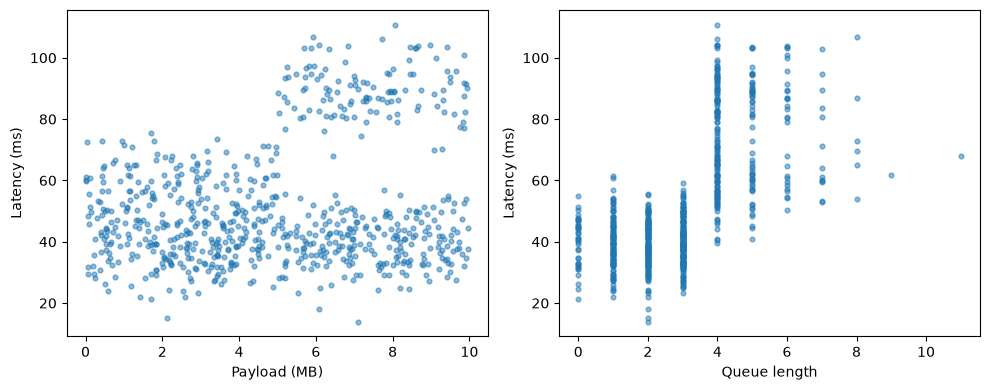

In [2]:
rng = np.random.default_rng(17)
n = 1200
payload = rng.uniform(0, 10, n)
queue = rng.poisson(3, n)
mean_latency = 40 + 20 * (queue > 3) + 30 * ((queue > 3) & (payload > 5))
latency = mean_latency + rng.normal(0, 8, n)
data = pd.DataFrame({"payload": payload, "queue": queue, "latency": latency})
train_valid, test = train_test_split(data, test_size=0.2, random_state=23)
train, valid = train_test_split(train_valid, test_size=0.25, random_state=23)
assert set(train.index).isdisjoint(valid.index)
assert set(train.index).isdisjoint(test.index)
assert set(valid.index).isdisjoint(test.index)
features = ["payload", "queue"]
X_train = train[features].to_numpy()
y_train = train["latency"].to_numpy()
print("Rows:", {"training": len(train), "validation": len(valid), "test": len(test)})
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, feature in zip(axes, features):
    ax.scatter(train[feature], y_train, s=12, alpha=0.5)
    ax.set(xlabel="Payload (MB)" if feature == "payload" else "Queue length", ylabel="Latency (ms)")
plt.tight_layout()
plt.show()

## 3. Fit the basic candidates and compare their surfaces

**Purpose:** Compare what four model types can represent, using identical training data.
The code creates each model and then calls `.fit(X_train, y_train)` on it.

### Main model classes in the next cell

| Class and setting | What it learns and predicts |
| --- | --- |
| `DummyRegressor(strategy="mean")` | Learns the training-target mean and predicts that number for every input. This simple baseline ignores the features. |
| `LinearRegression()` | Fits $\hat y=b+w_s s+w_q q$ by least squares. Its prediction is a plane with constant slopes, so it cannot exactly represent the abrupt jumps in this simulation. |
| `DecisionTreeRegressor(max_depth=1, ...)` | Fits a regression stump: one question, with a learned mean prediction in each of its two leaves. |
| `DecisionTreeRegressor(max_depth=2, ...)` | Allows up to two split decisions along a root-to-leaf path, hence at most four leaves. It can split on queue first and then on payload in a child. |

A **leaf** is a terminal group of training rows. A regression tree predicts their mean.
These trees use the default squared-error criterion to choose splits. `max_depth` limits
the number of decisions on a path, not the total number of tree nodes.
`random_state=31` makes any randomized feature ordering and tie handling reproducible.

The dictionary `models` stores the fitted objects under readable names. Their shared
`.fit()` and `.predict()` interface lets us handle them with the same loop.

### Checking the stump and drawing the surfaces

`stump_candidates` repeats our manual split search on the 720 training rows.
`np.where(is_left, left_mean, right_mean)` assigns the appropriate leaf mean to each row.
The assertion compares these manual predictions with the fitted library stump.
In the saved run the split is **queue $\le3.5$**, equivalent to queue $\le3$ because
queue lengths are integers. Its two predictions are about 39.6 and 73.9 ms.
The high-queue leaf mixes the 60 ms and 90 ms regimes because a stump cannot split again.

The remaining functions prepare a diagnostic picture:

- `np.linspace` and `np.arange` create fixed payload and queue values.
- `np.meshgrid` forms all pairs; `np.column_stack` turns them into an input table.
- `.predict(grid)` predicts latency at each pair; `.reshape(...)` restores the grid shape.
- `ax.pcolormesh(...)` draws a colored prediction surface. All panels use the same color scale.

Compare the flat baseline, sloping linear surface, and rectangular constant regions of the trees
with the known mean. The grid and true mean are used only for this explanation, not for fitting
or selection. A depth-two tree can represent the three true regimes, but may also use an extra
split to follow noise in a region whose true mean is constant.

Custom stump: queue <= 3.5
Leaf means (ms): 39.58249175020302 73.92548338872686


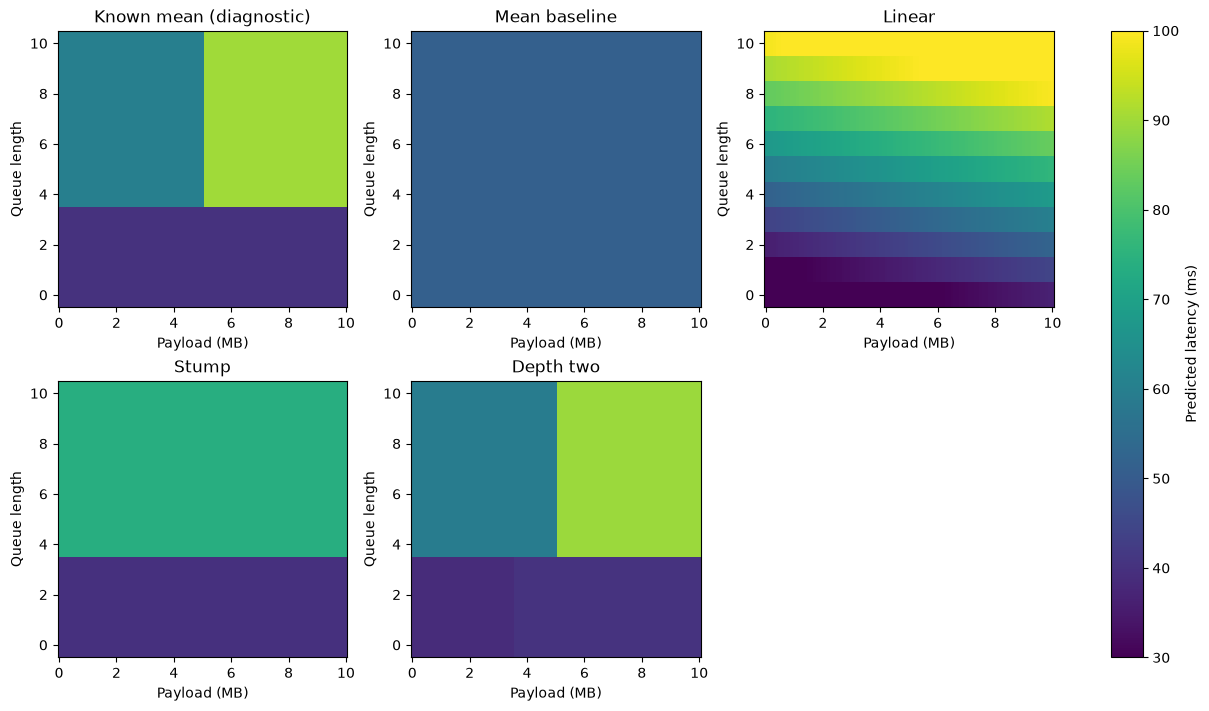

In [3]:
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear": LinearRegression(),
    "Stump": DecisionTreeRegressor(max_depth=1, random_state=31),
    "Depth two": DecisionTreeRegressor(max_depth=2, random_state=31),
}
for model in models.values():
    model.fit(X_train, y_train)

candidates = stump_candidates(X_train, y_train)
best = candidates.loc[candidates["child RSS"].idxmin()]
feature_index = int(best["feature"])
threshold = float(best["threshold"])
is_left = X_train[:, feature_index] <= threshold
left_mean = y_train[is_left].mean()
right_mean = y_train[~is_left].mean()
custom_prediction = np.where(is_left, left_mean, right_mean)
np.testing.assert_allclose(custom_prediction, models["Stump"].predict(X_train), atol=1e-10)
print("Custom stump:", features[feature_index], "<=", threshold)
print("Leaf means (ms):", left_mean, right_mean)

s_grid = np.linspace(0, 10, 101)
q_grid = np.arange(0, 11)
S, Q = np.meshgrid(s_grid, q_grid)
grid = np.column_stack([S.ravel(), Q.ravel()])
surfaces = {"Known mean (diagnostic)": 40 + 20 * (Q > 3) + 30 * ((Q > 3) & (S > 5))}
for name, model in models.items():
    surfaces[name] = model.predict(grid).reshape(S.shape)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for ax, (name, surface) in zip(axes.ravel(), surfaces.items()):
    picture = ax.pcolormesh(S, Q, surface, shading="auto", vmin=30, vmax=100, cmap="viridis")
    ax.set(title=name, xlabel="Payload (MB)", ylabel="Queue length")
axes.ravel()[-1].set_visible(False)
fig.colorbar(picture, ax=list(axes.ravel()[:-1]), label="Predicted latency (ms)")
plt.show()

## 4. Choose a pruning penalty using training cross-validation

**Purpose:** Reduce an overly detailed tree without selecting its size from test results.
**Pruning** removes branches that contribute too little to reducing training error relative
to their complexity. The cost-complexity criterion is

$$R_\alpha(T)=\frac{1}{n_{\mathrm{fit}}}\sum_{\ell\in\operatorname{leaves}(T)}
\operatorname{RSS}(A_\ell)+\alpha\,|\operatorname{leaves}(T)|.$$

Here $T$ is a tree, $A_\ell$ contains the training rows in leaf $\ell$, and $n_{\mathrm{fit}}$
is the number of fitting rows. The first term is mean training squared error; the second
penalizes the number of leaves. Larger $\alpha$ favors simpler trees. The library parameter
`ccp_alpha` is this $\alpha$; zero means no cost-complexity pruning.

### Main functions and options in the next cell

| Function or option | Role here |
| --- | --- |
| `KFold(n_splits=5, shuffle=True, random_state=23)` | Supplies five pairs of fitting/scoring row positions. It does not fit a model itself. |
| `DecisionTreeRegressor(min_samples_leaf=2, ccp_alpha=alpha, ...)` | Fits a tree requiring at least two fitting rows per leaf, then applies the specified pruning penalty. No maximum depth is imposed here. |
| `mean_squared_error(y, prediction)` | Computes mean squared error; `np.sqrt(...)` converts it to RMSE in milliseconds. |
| `.get_n_leaves()` | Counts terminal prediction regions of a fitted tree. |
| `np.mean(...)` / `np.std(..., ddof=1)` | Summarize the five fold errors by their mean and sample standard deviation. |
| `ax.set_xscale("symlog", ...)` | Uses an axis that displays zero and widely separated positive alpha values clearly. |

For each $\alpha\in\{0,0.01,0.1,1,5,10,25,50,100\}$, fit on **576 training rows**
and score on the other **144**, repeating until every fold has been held out once.
The same folds are reused for each alpha. Select the smallest average fold RMSE; an exact
tie uses the first, smallest alpha in the grid. `fold SD` describes variation between fold
scores, not a confidence interval. Validation and test rows do not participate.

For the plots, a separate tree at each alpha is also fitted on all 720 training rows.
Its training RMSE and leaf count describe that full-training fit; fold trees can differ.
The first plot contrasts training error with held-out cross-validation error. A very low
training error alongside a larger cross-validation error suggests overfitting.

In the saved run, the unpruned tree has 311 leaves and cross-validation RMSE about 10.34 ms.
Several pruning settings tie near 7.87 ms; the rule selects $\alpha=1$.
The code then fits that configuration on all 720 training rows and adds it to `models`
as `Pruned (CV)`. This fitted tree has three leaves. Its alpha and fitted parameters remain
fixed during validation and test evaluation.

,alpha,CV RMSE,fold SD,training RMSE,full-training leaves
0,0.00,10.341488,0.361403,4.457772,311
1,0.01,10.349696,0.357132,4.475837,276
2,0.10,9.949302,0.244392,5.151659,153
3,1.00,7.867662,0.521731,7.848599,3
4,5.00,7.867662,0.521731,7.848599,3
5,10.00,7.867662,0.521731,7.848599,3
6,25.00,7.867662,0.521731,7.848599,3
7,50.00,7.867662,0.521731,7.848599,3
8,100.00,11.837033,0.483074,11.826060,2


Frozen alpha: 1.0


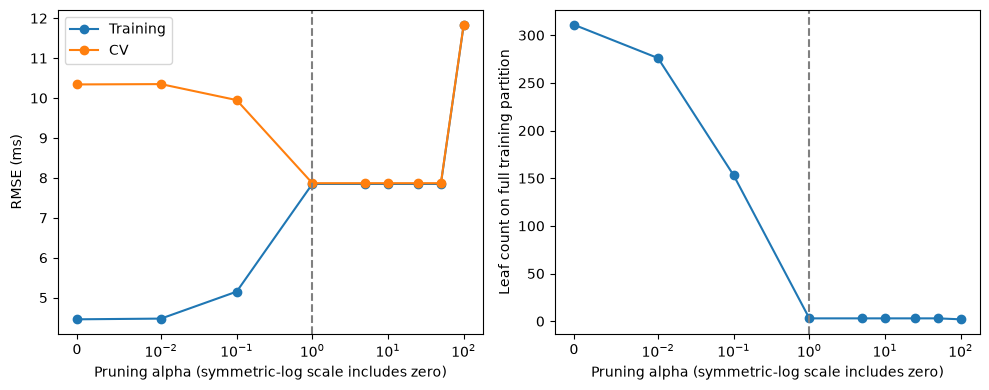

In [4]:
alphas = np.array([0, 0.01, 0.1, 1, 5, 10, 25, 50, 100])
folds = list(KFold(n_splits=5, shuffle=True, random_state=23).split(X_train))
cv_rows = []
for alpha in alphas:
    errors = []
    for fit_rows, score_rows in folds:
        model = DecisionTreeRegressor(min_samples_leaf=2, ccp_alpha=alpha, random_state=31)
        model.fit(X_train[fit_rows], y_train[fit_rows])
        errors.append(np.sqrt(mean_squared_error(y_train[score_rows], model.predict(X_train[score_rows]))))
    full_tree = DecisionTreeRegressor(min_samples_leaf=2, ccp_alpha=alpha, random_state=31)
    full_tree.fit(X_train, y_train)
    cv_rows.append({"alpha": alpha, "CV RMSE": np.mean(errors), "fold SD": np.std(errors, ddof=1),
                    "training RMSE": np.sqrt(mean_squared_error(y_train, full_tree.predict(X_train))),
                    "full-training leaves": full_tree.get_n_leaves()})
cv_results = pd.DataFrame(cv_rows)
best_alpha = float(cv_results.loc[cv_results["CV RMSE"].idxmin(), "alpha"])
models["Pruned (CV)"] = DecisionTreeRegressor(min_samples_leaf=2, ccp_alpha=best_alpha, random_state=31)
models["Pruned (CV)"].fit(X_train, y_train)
display(cv_results)
print("Frozen alpha:", best_alpha)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(alphas, cv_results["training RMSE"], "o-", label="Training")
axes[0].plot(alphas, cv_results["CV RMSE"], "o-", label="CV")
axes[0].set(ylabel="RMSE (ms)")
axes[0].legend()
axes[1].plot(alphas, cv_results["full-training leaves"], "o-")
axes[1].set(ylabel="Leaf count on full training partition")
for ax in axes:
    ax.set_xscale("symlog", linthresh=0.01)
    ax.set_xlabel("Pruning alpha (symmetric-log scale includes zero)")
    ax.axvline(best_alpha, color="gray", linestyle="--")
plt.tight_layout()
plt.show()

## 5. Bootstrap stability: boundaries and fixed inputs

**Purpose:** See how tree predictions change when the training sample changes slightly.
A **bootstrap resample** draws 720 row positions **with replacement** from the 720 training
rows: a row can appear several times, while other rows are omitted. It is not a new set of
independently simulated requests.

We make 30 such resamples and fit both a depth-two tree and the selected pruning configuration
on each. Keep alpha fixed: this investigates stability of a chosen configuration rather than
repeating model selection. These temporary trees are stored in `bootstrap_models`; the original
models used for the final evaluation remain in `models`.

### Main functions and attributes in the next cell

| Function or attribute | Role here |
| --- | --- |
| `bootstrap_rng.integers(0, len(train), len(train))` | Draws the row positions with replacement for one bootstrap resample. |
| `model.tree_` | Gives access to the fitted tree structure. Its `node_count` counts all nodes. |
| `model.tree_.feature[node]` | Gives the split-feature index at a non-leaf node; a negative value marks a leaf here. |
| `model.tree_.threshold[node]` | Gives that node's splitting threshold. Node 0 is the root. |
| `.predict(profiles.to_numpy())` | Predicts latency at the same five specified inputs for every fitted tree. |
| `pd.crosstab(...)` | Counts which feature was chosen at the root across resamples. |
| `.groupby(...).agg(...)` | Groups recorded results and computes counts, medians, ranges, means, or standard deviations. |

The profiles include ordinary inputs inside regimes and inputs close to the payload boundary:
4.99 MB and 5.01 MB at queue length 4. A small change in a fitted threshold near 5 MB can
send such a request to a different leaf, changing its predicted latency substantially.
Queue length is integer-valued, so 3 and 4 are the nearest possible values on opposite sides
of its boundary. The listed profiles illustrate different positions, not a controlled one-feature
comparison between every pair of rows.

Read the output in three parts:

1. **Root feature counts:** does each resample start with the same variable?
2. **Pooled split thresholds:** how much do thresholds vary? These pool all internal nodes
   by feature; they do not match corresponding branches across trees. Extra noise-fitting
   splits can therefore appear far from the true boundary.
3. **Fixed-input prediction variability:** `mean` and `std` summarize each profile's 30 predictions,
   both in milliseconds. Large `std` means the predicted value is sensitive to resampling.

In the saved run, queue is always the root feature, yet the profile just above the payload
boundary has a prediction standard deviation around 13 ms. A stable first split does not
make every prediction stable. These summaries are a stability diagnostic, not formal
confidence intervals or a substitute for held-out prediction error.

In [5]:
profiles = pd.DataFrame({"payload": [2, 2, 4.99, 5.01, 8], "queue": [1, 3, 4, 4, 6]},
                        index=["away: low queue", "at low-queue edge", "just below payload edge",
                               "just above payload edge", "away: high regime"])
bootstrap_rng = np.random.default_rng(47)
split_rows = []
prediction_rows = []
for repeat in range(30):
    rows = bootstrap_rng.integers(0, len(train), len(train))
    bootstrap_models = {
        "Depth two": DecisionTreeRegressor(max_depth=2, random_state=100 + repeat),
        "Pruned (CV)": DecisionTreeRegressor(min_samples_leaf=2, ccp_alpha=best_alpha, random_state=100 + repeat),
    }
    for name, model in bootstrap_models.items():
        model.fit(X_train[rows], y_train[rows])
        for node in range(model.tree_.node_count):
            j = model.tree_.feature[node]
            if j >= 0:
                split_rows.append({"model": name, "feature": features[j],
                                   "threshold": model.tree_.threshold[node], "root": node == 0})
        predictions = model.predict(profiles.to_numpy())
        for profile, prediction in zip(profiles.index, predictions):
            prediction_rows.append({"model": name, "profile": profile, "prediction (ms)": prediction})
split_results = pd.DataFrame(split_rows)
prediction_results = pd.DataFrame(prediction_rows)
display(profiles)
print("Root feature counts across resamples")
display(pd.crosstab(split_results.loc[split_results["root"], "model"],
                    split_results.loc[split_results["root"], "feature"]))
print("All split thresholds pooled by feature (not matched node-by-node)")
display(split_results.groupby(["model", "feature"])["threshold"].agg(["count", "median", "min", "max"]))
print("Fixed-input prediction variability")
display(prediction_results.groupby(["profile", "model"])["prediction (ms)"].agg(["mean", "std"]).round(3))

,payload,queue
away: low queue,2.00,1
at low-queue edge,2.00,3
just below payload edge,4.99,4
just above payload edge,5.01,4
away: high regime,8.00,6


Root feature counts across resamples


feature,queue
model,
Depth two,30
Pruned (CV),30


All split thresholds pooled by feature (not matched node-by-node)


count    median       min       max
model       feature                                     
Depth two   payload     58  5.008393  0.068748  9.850002
            queue       32  3.500000  2.500000  3.500000
Pruned (CV) payload     90  5.008393  0.068748  9.702036
            queue       35  3.500000  1.500000  7.500000

Fixed-input prediction variability


mean     std
profile                 model                      
at low-queue edge       Depth two    39.190   0.903
                        Pruned (CV)  39.227   1.176
away: high regime       Depth two    89.346   0.762
                        Pruned (CV)  89.303   1.639
away: low queue         Depth two    39.052   0.780
                        Pruned (CV)  38.897   1.443
just above payload edge Depth two    82.297  12.911
                        Pruned (CV)  82.036  12.774
just below payload edge Depth two    59.046   0.562
                        Pruned (CV)  59.040   0.587

## 6. Validation audit and final test evaluation

**Purpose:** Evaluate the fitted models on requests excluded from fitting and report their
prediction error, tree size, and local prediction time.

First, the code computes validation RMSE for all five prespecified fits. This is an additional
check: it does not change alpha or select a replacement model. Then it evaluates all five on
the test partition. The pruned configuration remains the one selected by training cross-validation.
Calling `.predict()` here uses existing models; no `.fit()` call is made.

For $m$ held-out rows with observed latencies $y_i$ and predictions $\hat y_i$,

$$\operatorname{RMSE}=\sqrt{\frac1m\sum_i(y_i-\hat y_i)^2},\qquad
\operatorname{MAE}=\frac1m\sum_i|y_i-\hat y_i|.$$

**Mean absolute error (MAE)** measures average absolute error. RMSE gives more weight to
large errors. Both are in milliseconds, and smaller is better.

### Main functions and methods in the next cell

| Function or method | Role here |
| --- | --- |
| `mean_squared_error(...)` / `mean_absolute_error(...)` | Compute squared and absolute prediction errors; take the square root of the former for RMSE. |
| `isinstance(model, DecisionTreeRegressor)` | Checks whether tree-specific size methods apply to this model. |
| `.get_depth()` | Returns the largest number of split decisions on a root-to-leaf path. |
| `.get_n_leaves()` | Counts terminal leaves, each storing a prediction. |
| `perf_counter()` | Reads a clock in seconds; subtract two readings to time one prediction call. |
| `np.median(timings)` | Summarizes 30 repeated prediction timings with their median. |

Depth and leaf count describe tree complexity. Missing values (`NaN`) in these columns mean
that the measures do not apply to the baseline or linear model.
`batch prediction time (ms)` measures a call for **all 240 test rows**, not one request.
Multiplication by 1,000 converts elapsed seconds to milliseconds. Repeating prediction does
not retrain the model or create 30 independent performance evaluations. These small timings
include call overhead and depend on the local machine; they are not portable speed guarantees.

In the saved run, test RMSE is about 19.10 ms for the constant baseline, 13.63 ms for the linear
model, 11.41 ms for the stump, 8.25 ms for the depth-two tree, and 8.27 ms for the pruned tree.
The latter uses three leaves rather than four. The small test difference between the two deeper
trees is not a reason to revise a setting after seeing the test data.

The simulator adds independent noise with standard deviation 8 ms. Even the true conditional
mean therefore has population RMSE 8 ms; a finite test score can fall above or below that value.
A result near 8 ms is consistent with capturing the main regime structure, not predicting the noise.

In [6]:
X_valid = valid[features].to_numpy()
validation_rows = []
for name, model in models.items():
    rmse = np.sqrt(mean_squared_error(valid["latency"], model.predict(X_valid)))
    validation_rows.append({"model": name, "validation RMSE (ms)": rmse})
display(pd.DataFrame(validation_rows).set_index("model"))

X_test = test[features].to_numpy()
y_test = test["latency"].to_numpy()
test_rows = []
for name, model in models.items():
    prediction = model.predict(X_test)
    timings = []
    for repeat in range(30):
        start = perf_counter()
        model.predict(X_test)
        timings.append(1000 * (perf_counter() - start))
    is_tree = isinstance(model, DecisionTreeRegressor)
    test_rows.append({"model": name, "test RMSE (ms)": np.sqrt(mean_squared_error(y_test, prediction)),
                      "test MAE (ms)": mean_absolute_error(y_test, prediction),
                      "depth": model.get_depth() if is_tree else None,
                      "leaves": model.get_n_leaves() if is_tree else None,
                      "batch prediction time (ms)": np.median(timings)})
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results.round(3))

,validation RMSE (ms)
model,
Mean baseline,20.418315
Linear,14.691684
Stump,12.299437
Depth two,8.605316
Pruned (CV),8.580704


,test RMSE (ms),test MAE (ms),depth,leaves,batch prediction time (ms)
model,,,,,
Mean baseline,19.101,15.316,NaN,NaN,0.010
Linear,13.634,10.867,NaN,NaN,0.047
Stump,11.414,8.897,1.0,2.0,0.088
Depth two,8.249,6.474,2.0,4.0,0.066
Pruned (CV),8.274,6.489,2.0,3.0,0.068


## Interpret the results

- Explain why the linear model cannot exactly represent the regime changes, even though it is easy to fit.
- Compare CV and training RMSE as alpha increases. The minimum training error need not identify the best tree.
- Which fixed inputs have unstable predictions? Split variation matters most when it changes routing.
- The generator has noise SD 8 ms. Even its exact mean cannot predict that independent noise.
- This simulator deliberately favors tree-shaped partitions. A different response relationship could favor a linear model.

**In the saved run:** CV selects alpha 1, leaving three leaves. Test RMSE is about
8.27 ms for that tree versus 13.63 ms for the additive linear model and 19.10 ms for
the mean baseline. The depth-two tree has four leaves and test RMSE about 8.25 ms.
Predictions just above the payload boundary vary substantially across resamples;
predictions well inside a regime are much steadier.